# Week 5 - Task 4: Model Evaluation & Prediction
**Deep Learning & Neural Networks | AI Internship**

**Goal:** Test the trained neural network (from Task 3) on the test set, calculate the test accuracy, look at the predictions and make a confusion matrix.

**Dataset:** Iris (UCI / scikit-learn)

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
tf.keras.utils.set_random_seed(42)   # same results every time I run
os.makedirs("Screenshots", exist_ok=True)
import matplotlib.pyplot as plt
# small helper: saves printed text as a picture to use as a screenshot
def save_output_image(text, filename):
    lines = text.split("\n")
    fig = plt.figure(figsize=(10, 0.28*len(lines)+0.6))
    fig.text(0.02, 0.98, text, family="monospace", fontsize=9, va="top")
    fig.savefig(filename, dpi=130, bbox_inches="tight", facecolor="white")
    plt.close(fig)

I0000 00:00:1791714955.654782    5306 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791714956.982684    5306 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Load the data and recreate the same test set
I use the same `random_state=42` split and scaler as before, so the test data is exactly the same unseen data.

In [2]:
df = pd.read_csv("iris.csv")
X = df[["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"]].values
encoder = LabelEncoder()
y = encoder.fit_transform(df["species"])      # setosa=0, versicolor=1, virginica=2
class_names = list(encoder.classes_)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)       # fit only on training data
X_test = scaler.transform(X_test)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (120, 4)  Test: (30, 4)


## Load the trained model

In [3]:
model = keras.models.load_model("../Task3_Train_and_Visualize/iris_ann.keras")
print("Model loaded")

Model loaded


## 1. Test the model and calculate test accuracy

In [4]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
out = ("TEST RESULTS\n"
       "------------------------------\n"
       f"Test loss     : {test_loss:.4f}\n"
       f"Test accuracy : {test_acc*100:.2f}%\n"
       f"Test samples  : {len(y_test)}")
print(out)
save_output_image(out, "Screenshots/01_test_accuracy.png")

TEST RESULTS
------------------------------
Test loss     : 0.0916
Test accuracy : 96.67%
Test samples  : 30


## 2. Generate predictions
The output layer gives a probability for each class. I take the class with the highest probability (`argmax`) as the prediction.

In [5]:
probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(probs, axis=1)

results = pd.DataFrame({
    "Actual": [class_names[i] for i in y_test],
    "Predicted": [class_names[i] for i in y_pred],
    "Confidence_%": (probs.max(axis=1) * 100).round(1),
})
results["Correct"] = np.where(results["Actual"] == results["Predicted"], "Yes", "No")
results.to_csv("predictions.csv", index=False)
results.head(10)

,Actual,Predicted,Confidence_%,Correct
0,setosa,setosa,100.000000,Yes
1,virginica,virginica,85.800003,Yes
2,versicolor,versicolor,97.199997,Yes
3,versicolor,versicolor,98.900002,Yes
4,setosa,setosa,100.000000,Yes
5,versicolor,versicolor,74.800003,Yes
6,setosa,setosa,100.000000,Yes
7,setosa,setosa,99.599998,Yes
8,virginica,virginica,97.199997,Yes
9,versicolor,versicolor,79.400002,Yes


## 3. Actual vs Predicted (first 10 examples)

In [6]:
out = "ACTUAL vs PREDICTED (first 10 test flowers)\n" + results.head(10).to_string()
print(out)
save_output_image(out, "Screenshots/02_actual_vs_predicted.png")

ACTUAL vs PREDICTED (first 10 test flowers)
       Actual   Predicted  Confidence_% Correct
0      setosa      setosa    100.000000     Yes
1   virginica   virginica     85.800003     Yes
2  versicolor  versicolor     97.199997     Yes
3  versicolor  versicolor     98.900002     Yes
4      setosa      setosa    100.000000     Yes
5  versicolor  versicolor     74.800003     Yes
6      setosa      setosa    100.000000     Yes
7      setosa      setosa     99.599998     Yes
8   virginica   virginica     97.199997     Yes
9  versicolor  versicolor     79.400002     Yes


## 4. Confusion matrix

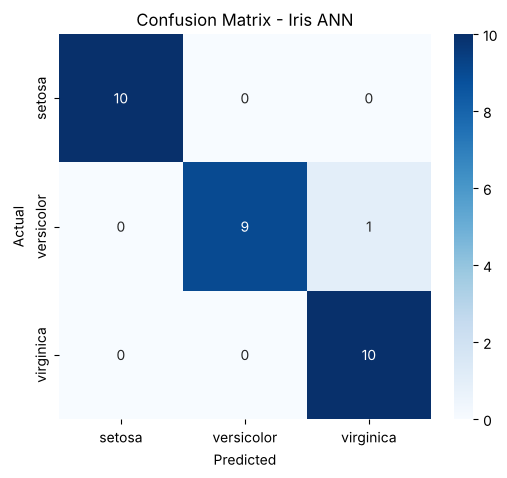

In [7]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Iris ANN")
plt.savefig("Screenshots/03_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

In [8]:
report = classification_report(y_test, y_pred, target_names=class_names)
print(report)
save_output_image("CLASSIFICATION REPORT\n" + report, "Screenshots/04_classification_report.png")

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



## 5. Incorrect predictions

In [9]:
wrong = results[results["Correct"] == "No"]
print("Number of wrong predictions:", len(wrong), "out of", len(results))
raw = scaler.inverse_transform(X_test)          # go back to original cm values
wrong_detail = pd.DataFrame(raw[wrong.index], columns=["sepal_length", "sepal_width", "petal_length", "petal_width"]).round(2)
wrong_detail = pd.concat([wrong.reset_index(drop=True), wrong_detail.reset_index(drop=True)], axis=1)
wrong_detail

Number of wrong predictions: 1 out of 30


,Actual,Predicted,Confidence_%,Correct,sepal_length,sepal_width,petal_length,petal_width
0,versicolor,virginica,65.0,No,6.7,3.0,5.0,1.7


## Explanation of the results

**Test accuracy:** The model got **96.67%** accuracy on the test set, which means 29 of the 30 unseen flowers were predicted correctly (test loss 0.0916).

**Confusion matrix:** All setosa and virginica flowers and all but one versicolor flower were predicted correctly. The only mistake is one **versicolor flower predicted as virginica**.

**Why was it wrong?** Looking at the wrong flower, its petal length is 5.0 cm and its petal width is 1.7 cm. These values are on the border between versicolor and virginica, because these two species overlap a little in the Iris data. The model was also not very sure about it, since its confidence was only 65%. Setosa is very different from the other two species, so the model never confused it.

**Conclusion:** The neural network works well on Iris. Since the test set has only 30 flowers, a single wrong prediction changes the accuracy by 3.3%, so I should not read too much into the exact number.